# Data Preparation

Whenever you open or reconnect to this page, it is important to always **run this code block first** before working on the other code blocks of the page. I created this dataset using [HDPulse data](https://hdpulse.nimhd.nih.gov/data-portal/home) under Healthcare System -> Insurance. The data shows how many people aged 18 - 64 were insured in 2023

In [1]:
import pandas as pd
# set float display format to comma as thousand separator and 2 digits after the decimal point
pd.options.display.float_format = '{:,.2f}'.format

df = pd.read_csv('https://raw.githubusercontent.com/qarnac/cs201/refs/heads/main/insured_by_states_18_64.csv')
df.info()

# It is critical to run this block first before running any of the following code blocks. Otherwise, data will not be ready in df.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             51 non-null     object 
 1   All_Percent       51 non-null     float64
 2   All_People        51 non-null     int64  
 3   White_Percent     51 non-null     float64
 4   White_People      51 non-null     int64  
 5   Black_Percent     51 non-null     float64
 6   Black_People      51 non-null     int64  
 7   AI_AN_Percent     51 non-null     float64
 8   AI_AN_People      51 non-null     int64  
 9   API_Percent       51 non-null     float64
 10  API_People        51 non-null     int64  
 11  Hispanic_Percent  51 non-null     float64
 12  Hispanic_People   51 non-null     int64  
dtypes: float64(6), int64(6), object(1)
memory usage: 5.3+ KB


A quick way to get descriptive statistics for numeric columns is to run the describe function.

In [2]:
df.describe()

,All_Percent,All_People,White_Percent,White_People,Black_Percent,Black_People,AI_AN_Percent,AI_AN_People,API_Percent,API_People,Hispanic_Percent,Hispanic_People
count,51.00,51.00,51.00,51.00,51.00,51.00,51.00,51.00,51.00,51.00,51.00,51.00
mean,89.90,"3,447,982.47",92.64,"2,060,351.25",88.58,"419,555.27",84.70,"16,408.20",92.07,"238,174.63",76.50,"602,070.04"
std,3.77,"3,915,733.08",2.81,"1,764,780.26",3.90,"503,924.22",6.57,"21,424.52",2.93,"535,982.29",7.61,"1,380,580.42"
min,78.40,"282,570.00",87.00,"166,705.00",78.40,"2,742.00",67.20,562.00,85.00,"3,542.00",61.60,"8,848.00"
25%,87.15,"950,184.50",90.55,"732,739.50",86.00,"35,048.50",81.75,"4,973.00",90.05,"26,341.00",72.80,"85,205.00"
50%,91.00,"2,344,505.00",93.20,"1,634,873.00",89.00,"190,036.00",86.00,"8,645.00",92.50,"82,972.00",76.30,"187,993.00"
75%,92.65,"4,216,251.00",94.70,"2,791,316.50",90.95,"681,280.00",89.05,"19,589.50",94.05,"237,468.50",81.15,"456,638.00"
max,96.50,"21,646,886.00",98.10,"7,454,149.00",95.80,"1,864,406.00",95.40,"101,187.00",97.60,"3,634,108.00",92.10,"8,352,387.00"


# Data wrangling

The original dataset contains 13 columns. But not all 13 columns are needed to answer every question we have on insurance coverage. The following code block creates a new DataFrame to focus on insurance coverage for all races combined.

In [3]:
selected_columns = ['State', 'All_Percent', 'All_People']
reduced_df = df[selected_columns].copy()
reduced_df.head(10)

,State,All_Percent,All_People
0,Alabama,87.30,2551999
1,Alaska,85.30,371125
2,Arizona,86.20,3690186
3,Arkansas,87.70,1535328
4,California,91.00,21646886
5,Colorado,90.80,3320582
6,Connecticut,92.10,1969760
7,Delaware,91.00,529719
8,District of Columbia,96.50,418918
9,Florida,84.50,10979148


We can use existing columns to create new columns.

The following code block shows how to create a new column to show the population of the states.

In [4]:
reduced_df['All_Population'] = reduced_df['All_People'] / reduced_df['All_Percent'] * 100
reduced_df.head(3)

,State,All_Percent,All_People,All_Population
0,Alabama,87.30,2551999,"2,923,252.00"
1,Alaska,85.30,371125,"435,082.06"
2,Arizona,86.20,3690186,"4,280,958.24"


The following code block add ranks to the states based on their rate of coverage.

In [5]:
reduced_df['All_Percent_Rank'] = reduced_df['All_Percent'].rank(ascending=False, method='min')
reduced_df.head(10)

,State,All_Percent,All_People,All_Population,All_Percent_Rank
0,Alabama,87.30,2551999,"2,923,252.00",37.00
1,Alaska,85.30,371125,"435,082.06",45.00
2,Arizona,86.20,3690186,"4,280,958.24",42.00
3,Arkansas,87.70,1535328,"1,750,659.06",36.00
4,California,91.00,21646886,"23,787,786.81",24.00
5,Colorado,90.80,3320582,"3,657,028.63",28.00
6,Connecticut,92.10,1969760,"2,138,718.78",15.00
7,Delaware,91.00,529719,"582,108.79",24.00
8,District of Columbia,96.50,418918,"434,111.92",1.00
9,Florida,84.50,10979148,"12,993,074.56",47.00


The following code block labels the states based on its population

In [6]:
size_bins = [0, 2000000, 5000000, 10000000, 30000000]
size_labels=['Small', 'Medium', 'Large', 'Very Large']
reduced_df['State_Size'] = pd.cut(reduced_df['All_Population'], bins=size_bins, labels=size_labels)
reduced_df.head(10)

,State,All_Percent,All_People,All_Population,All_Percent_Rank,State_Size
0,Alabama,87.30,2551999,"2,923,252.00",37.00,Medium
1,Alaska,85.30,371125,"435,082.06",45.00,Small
2,Arizona,86.20,3690186,"4,280,958.24",42.00,Medium
3,Arkansas,87.70,1535328,"1,750,659.06",36.00,Small
4,California,91.00,21646886,"23,787,786.81",24.00,Very Large
5,Colorado,90.80,3320582,"3,657,028.63",28.00,Medium
6,Connecticut,92.10,1969760,"2,138,718.78",15.00,Medium
7,Delaware,91.00,529719,"582,108.79",24.00,Small
8,District of Columbia,96.50,418918,"434,111.92",1.00,Small
9,Florida,84.50,10979148,"12,993,074.56",47.00,Very Large


In [7]:
reduced_df['State_Size'].value_counts()

,count
State_Size,
Small,21
Medium,18
Large,8
Very Large,4


# Bar charts

Bar charts are one of the most common and effective ways to visualize data. They are intuitive and easy to read.

In a bar chart:
- Each **bar** represents a category.
- The **height** of the bar shows the value associated with that category.
- Bars can be grouped or stacked to show comparisons across multiple variables.

Before generating bar charts, the following code block use row filtering to create a DataFrame with data from our four neighboring states.


Bar charts are one of the most common and effective ways to visualize data. They are intuitive and easy to read.

In a bar chart:
- Each **bar** represents a category.
- The **height** of the bar shows the value associated with that category.
- Bars can be grouped or stacked to show comparisons across multiple variables.

The following code block use the pandas' `plot` function to set up a bar chart:

*  The `kind` parameter is set to `'bar'`, indicating a **bar chart** is to be created.
*  The `x` parameter indicates the column from which the values for the **x-axis** will be drawn. It is set to the `'State'` column.
*  The `y` parameter indicates the column from which the values for the y-axis will be drawn. It is set to the `'All_Races'` column.
*  The `figsize` parameter helps set the figure size as in `plt.figure` function.
*  The `title` parameter specifies the title for the graph.
*  The `xlabel` and `ylabels` parameters specify the labels to be put on the respective axis.
*  The `legend` parameter decides whether to show legend in the graph.
*  The `rot` parameter specifies rotation of x-tick labels.


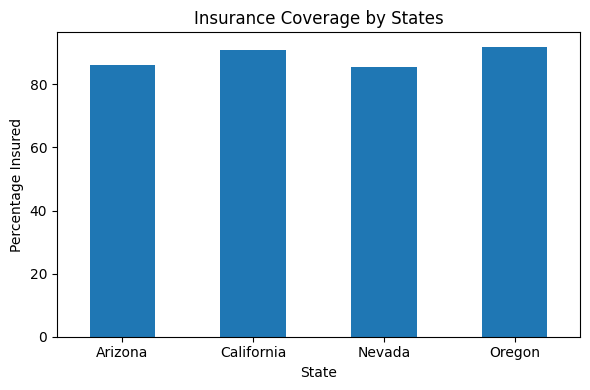

In [8]:
import matplotlib.pyplot as plt     # import appropriate library

# It's too much to show all 50 states in a bar chart. We can choose the states to compare.
selected_states = ['Arizona', 'California', 'Nevada', 'Oregon']
condition = reduced_df['State'].isin(selected_states)
chart_df = reduced_df[condition].copy()

# create the bar chart
chart_df.plot(kind='bar', x='State', y='All_Percent', figsize=(6, 4),
              title='Insurance Coverage by States',
              ylabel='Percentage Insured',
              legend=False,
              rot=0
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart


The above bar chart helps visualize a few things:

*  All four states have higher than 80% insurance coverage.
*  Oregon has the highest coverage among the four states.
*  Nevada has the lowest coverage among the four states.

The y parameter can be set to multiple columns in the dataset to support comparisons.

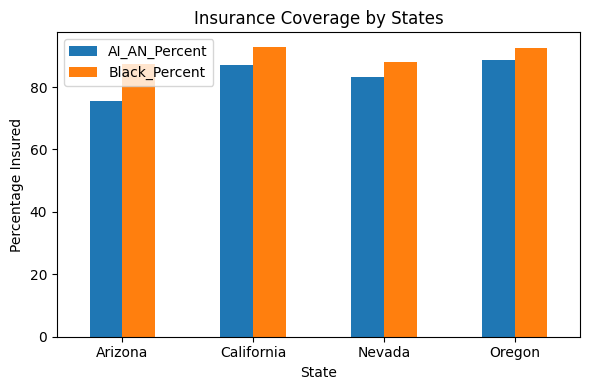

In [9]:
import matplotlib.pyplot as plt     # import appropriate library

# This time we want to compare coverage for different races
selected_columns = ['State', 'White_Percent', 'Black_Percent', 'Hispanic_Percent', 'AI_AN_Percent', 'API_Percent']
percent_df = df[selected_columns].copy()
selected_states = ['Arizona', 'California', 'Nevada', 'Oregon']
condition = percent_df['State'].isin(selected_states)
chart_df = percent_df[condition]

# create the bar chart
chart_df.plot(kind='bar',
              x='State',
              y=['AI_AN_Percent', 'Black_Percent'],
              figsize=(6, 4),
              title='Insurance Coverage by States',
              ylabel='Percentage Insured',
              legend=True,
              rot=0
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart


# Histograms

A **histogram** is a graph that shows how many values fall into different ranges (called bins). The height of each bar tells how many states fall into the range for that bin. In this way, a histogram can help us see patterns:
    *  Is it symmetric, left-skewed, right-skewed, bimodal…?
    *  Are there outliers?

The `plot` function we used for bar charts can also be used to create a histogram as shown in the following code block. There are additional parameters for the plot function we can adjust.
*  The `y` parameter specifies the numeric column whose values will be counted against the bins.
*  The `bins` parameter specifies the number of bins to be used.
*  The `range` parameter specifies the lower and upper bounds of the bins.
*  The `color` parameter specifies the color of the bars.
*  The `edgecolor` parameter specifies the color of the edges for the bars.
*  The `alpha` parameter specifies the level of transparency for the bars. 0 is fully transparent and 1 is fully opaque.
*  The `legend` parameter indicates whether to show the legend of the graph.


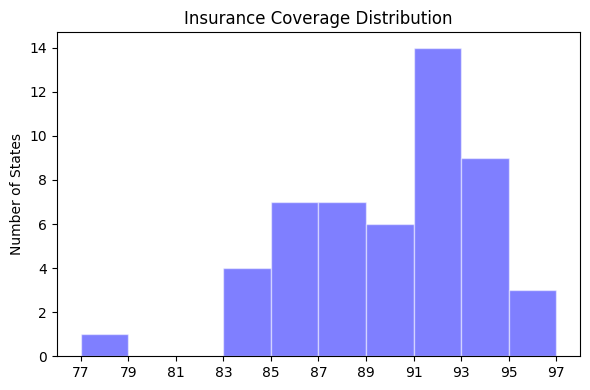

In [17]:
import matplotlib.pyplot as plt     # import appropriate library
import numpy as np

# create the bar chart
boundaries = np.arange(77,98, 2)
ax = reduced_df.plot(kind='hist', y='All_Percent',
                  figsize=(6, 4),
                  title='Insurance Coverage Distribution',
                  ylabel='Number of States',
                  bins=boundaries,
                  color='blue',
                  edgecolor='white',
                  alpha=0.5,
                  legend=False
)
ax.set_xticks(boundaries)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

The above histogram shows that there are
*  1 states with under 80% coverage.
*  4 states between 83 and 85, including 83 but excluding 85
*  7 states between 85 and 87, including 85 but excluding 87
*  And so on so forth.

The bins for histograms are left inclusive and right exclusive.

The following code block shows the distribution of coverage for states whose number of people insured are between 1 and 8 million.

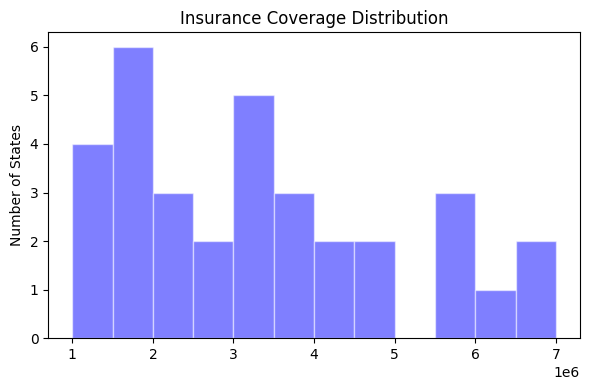

In [18]:
import matplotlib.pyplot as plt     # import appropriate library

# create the bar chart
reduced_df.plot(kind='hist', y='All_People',
                  figsize=(6, 4),
                  title='Insurance Coverage Distribution',
                  ylabel='Number of States',
                  bins=12,
                  range=(1000000, 7000000),
                  color='blue',
                  edgecolor='white',
                  alpha=0.5,
                  legend=False
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

The above histograph shows that there are
*  4 states whose insurance coverage for all races are between 1 and 1.5 million, including 1 million but excluding 1.5 million.
*  6 states whose insurance coverage for all races are between 1.5 and 2 million, including 1.5 million but excluding 2 million.
*  3 states for between 2 and 2.5, etc.

The bins for these histograms are left inclusive and right exclusive.

# Scatter plots

Scatter plots are a powerful way to explore relationships between two numerical variables, making them especially useful for our dataset. For example, we can examine whether states with higher overall insurance coverage also tend to have higher coverage for specific racial groups, or whether populations of different sizes show more variability in coverage rates. By displaying each state as a dot/circle, scatter plots help reveal patterns, clusters, and outliers that might be hard to see in tables alone, offering an intuitive starting point for deeper analysis.

The `plot` function we used for bar charts and histograms can also be used to create a histogram as shown in the following code block.

*  We need to set the `kind` parameter to `'scatter'` instead of `'bar'` or `'hist'`.
*  The `x` parameter specifies the column whose values will be used for the x-axis.
*  The `y` parameter specifies the column whose values will be used for the y-axis.
*  The `figsize` parameter specifies the width and height of the figure.
*  The `alpha` parameter specifies the level of transparency for each dot, 0 for fully transparent and 1 for fully opaque. The default value is 1.
*  The `s` parameter specifies the size of the dots, 20 for a small dot, 50 - 80 for a medium dot, and 150 - 300 for a large dot.
*  The `grid` parameter specifies whether to show a grid in the background. The default value is `False`.

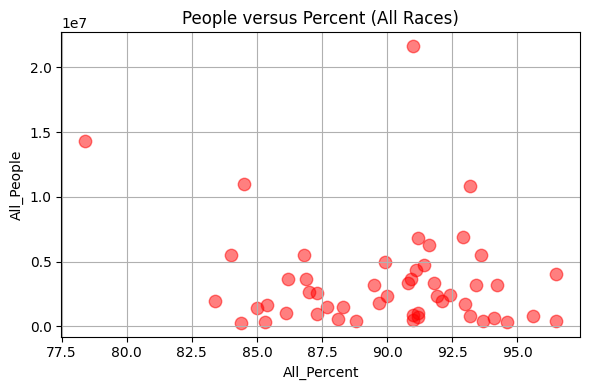

In [20]:
import matplotlib.pyplot as plt     # import appropriate library

# create a scatter plot
df.plot(kind='scatter',             #Indicate the kind of plot to be generated
        x='All_Percent',            #Identify the column for the x_axis
        y='All_People',             #Identify the column for the y-axis
        figsize=(6, 4),             #Set up the width and height of the graph
        title='People versus Percent (All Races)',  #Set up the title of the graph
        s=80,                       #Indicate the size of each dot
        alpha=0.5,                  #Indicate the level of transparency
        color='red',                #Indicate the color for the dots
        grid=True                   #Decide whether to use grid
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

The above scatter plot shows the following
*  Each dot in the graph represent one state. Some dots are overlapping with each other, indicating those states have similar percentage and people coverages.
*  The x-axis are marked by ranges of the percentage values.
*  The y-axis are marked by ranges of the people insured. The 1e7 on the top indicates a unit of 10 million.
*  The left most dot in the graph is for a state with the lowest percentage coverage (around 78%). Its corresponding y value indicates that close to 15 million people were insured in that state.
*  The highest dot in the graph is for a state with the highest number of people insured (over 20 million). Its corresponding x value indicates that percentage coverage for that state is around 91%.
*  There is no pattern showing that higher percentage coverages correspond to higher number of people covered for the states.

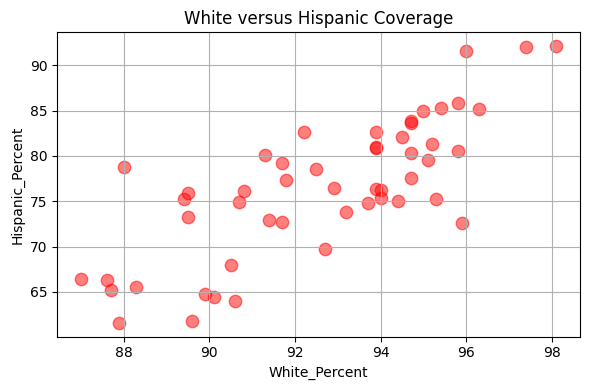

In [ ]:
import matplotlib.pyplot as plt     # import appropriate library

# create a scatter plot
df.plot(kind='scatter',             #Indicate the kind of plot to be generated
        x='White_Percent',          #Identify the column for the x_axis
        y='Hispanic_Percent',       #Identify the column for the y-axis
        figsize=(6, 4),             #Set up the width and height of the graph
        title='White versus Hispanic Coverage',  #Set up the title of the graph
        s=80,                       #Indicate the size of each dot
        alpha=0.5,                  #Indicate the level of transparency
        color='red',                #Indicate the color for the dots
        grid=True                   #Decide whether to use grid
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

This plot presents a visible trend of relationship between coverages for the two races. States (dots) that have higher coverage for White tends to have higher coverage for Hispanic too.